In [1]:

import pandas as pd

df = pd.read_csv("loan_prediction.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [2]:

# 1. Check dataset size
print("Dataset shape:", df.shape)

# 2. Check column names
print("\nColumns:")
print(df.columns.tolist())

# 3. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 4. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Check loan approval status
print("\nLoan status counts:")
print(df["Loan_Status"].value_counts())


Dataset shape: (614, 13)

Columns:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

Missing values:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Duplicate rows: 0

Loan status counts:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [3]:

# Make a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Fill missing values in text columns with the most common value
for col in df_clean.select_dtypes(include="object").columns:
    if col != "Loan_ID" and df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# Fill missing values in numeric columns with the median
for col in df_clean.select_dtypes(include="number").columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Data cleaning completed!")
print("Cleaned dataset shape:", df_clean.shape)
print("\nRemaining missing values:", df_clean.isnull().sum().sum())


Data cleaning completed!
Cleaned dataset shape: (614, 13)

Remaining missing values: 0


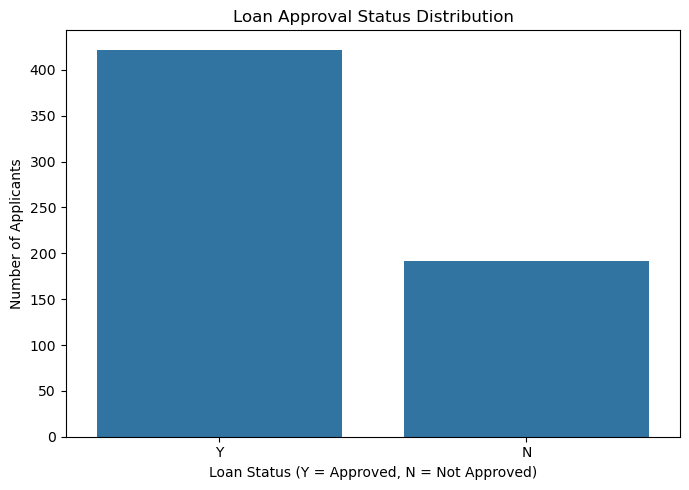

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count approved and rejected loans
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="Loan_Status")

plt.title("Loan Approval Status Distribution")
plt.xlabel("Loan Status (Y = Approved, N = Not Approved)")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.savefig("chart1_loan_status.png", dpi=300)
plt.show()


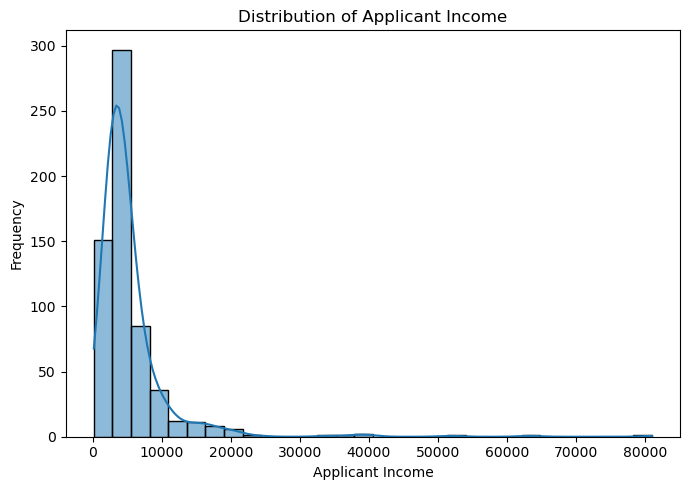

In [5]:

plt.figure(figsize=(7, 5))
sns.histplot(data=df_clean, x="ApplicantIncome", bins=30, kde=True)

plt.title("Distribution of Applicant Income")
plt.xlabel("Applicant Income")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("chart2_applicant_income.png", dpi=300)
plt.show()


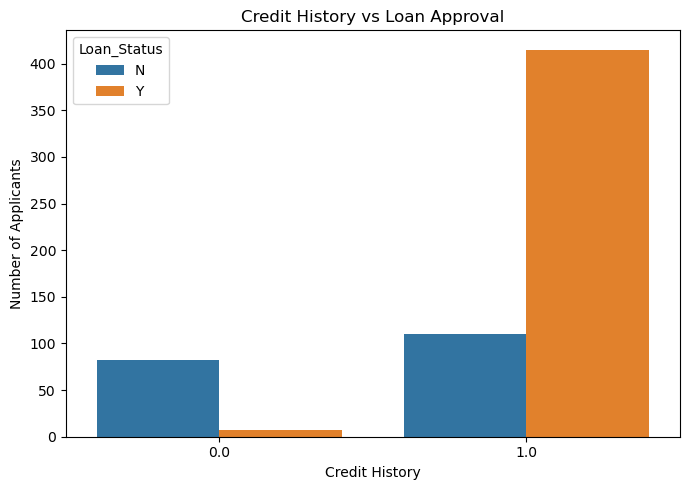

In [6]:

plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="Credit_History", hue="Loan_Status")

plt.title("Credit History vs Loan Approval")
plt.xlabel("Credit History")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.savefig("chart3_credit_history.png", dpi=300)
plt.show()


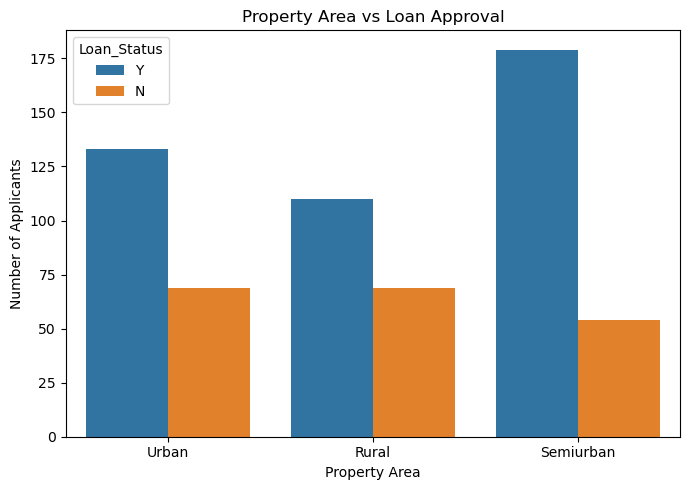

In [7]:

plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="Property_Area", hue="Loan_Status")

plt.title("Property Area vs Loan Approval")
plt.xlabel("Property Area")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.savefig("chart4_property_area.png", dpi=300)
plt.show()


In [8]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare the data
model_data = df_clean.copy()

# Remove applicant ID because it does not help predict approval
model_data = model_data.drop(columns=["Loan_ID"], errors="ignore")

# Separate input features and target
X = model_data.drop(columns=["Loan_Status"])
y = model_data["Loan_Status"]

# Convert text columns into numbers
X = pd.get_dummies(X, drop_first=True)

# Convert target labels Y and N into 1 and 0
y = y.map({"Y": 1, "N": 0})

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train the model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate the model
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=["Not Approved", "Approved"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 83.74 %

Classification Report:
              precision    recall  f1-score   support

Not Approved       0.80      0.63      0.71        38
    Approved       0.85      0.93      0.89        85

    accuracy                           0.84       123
   macro avg       0.82      0.78      0.80       123
weighted avg       0.83      0.84      0.83       123


Confusion Matrix:
[[24 14]
 [ 6 79]]


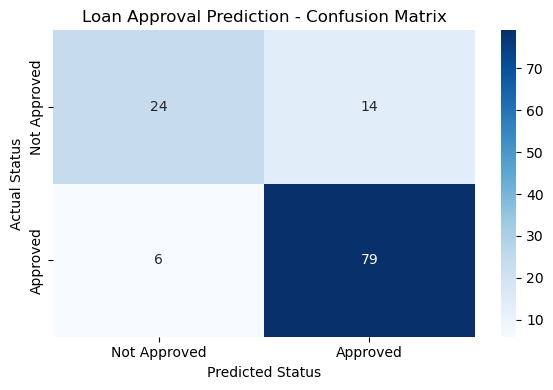

In [9]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Not Approved", "Approved"],
    yticklabels=["Not Approved", "Approved"]
)

plt.title("Loan Approval Prediction - Confusion Matrix")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.tight_layout()
plt.savefig("chart5_confusion_matrix.png", dpi=300)
plt.show()


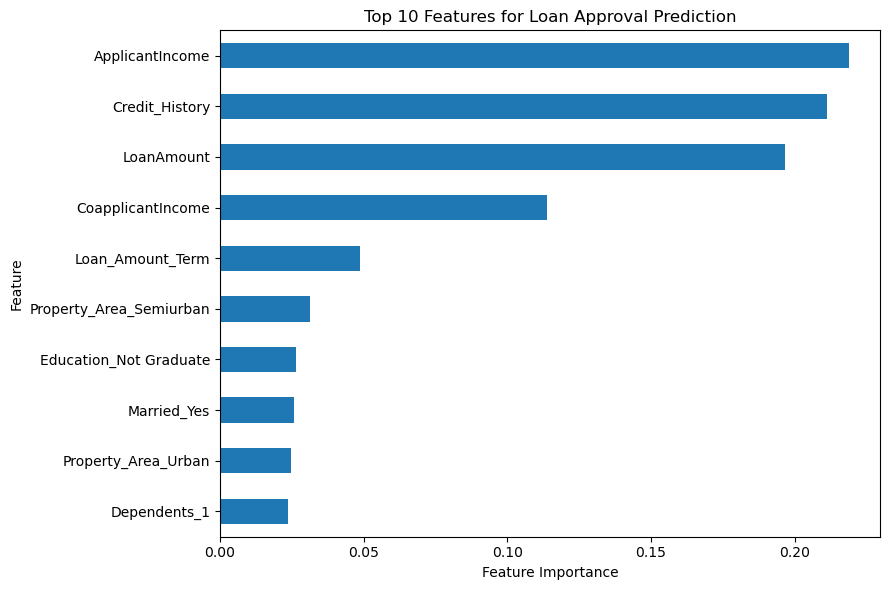

In [10]:

importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 6))
importance.sort_values().plot(kind="barh")

plt.title("Top 10 Features for Loan Approval Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("chart6_feature_importance.png", dpi=300)
plt.show()


In [11]:

import joblib

joblib.dump(model, "loan_approval_model.pkl")
joblib.dump(list(X_train.columns), "model_features.pkl")

print("Model and feature list saved successfully!")


Model and feature list saved successfully!
